In [18]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

# Example data
X, _ = make_blobs(
    n_samples=400,
    centers=3,
    cluster_std=1.0,
    random_state=42
)


In [19]:
# Try several values of k
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        tol=1e-2,
        random_state=42,
        n_init=5
    )
    model.fit(X)
    inertias.append(model.inertia_)

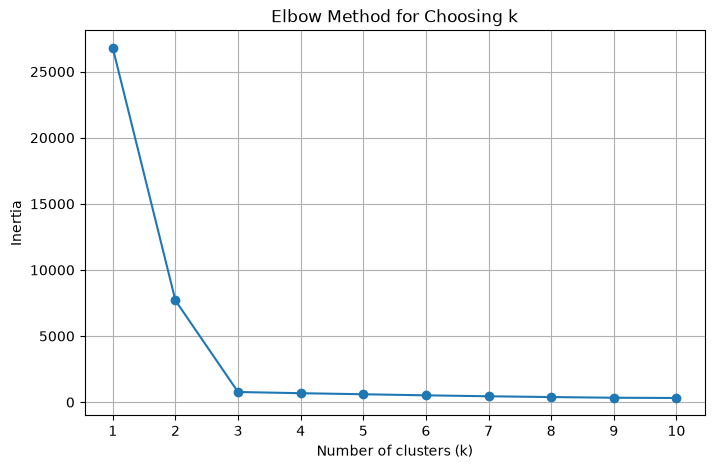

In [20]:
# Plot inertia against number of clusters
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing k")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [21]:
# K-means stops when centroid movement is smaller than this value.
kmeans = KMeans(
    n_clusters=3,
    tol=1e-4,
    max_iter=300,
    random_state=42,
    n_init=10
)

In [22]:
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[-2.

In [23]:
print("Centroids:\n", kmeans.cluster_centers_)
print("Cluster labels:\n", kmeans.labels_)
print("Iterations used:", kmeans.n_iter_)
print("Inertia:", kmeans.inertia_)

Centroids:
 [[-2.58785774  9.04994921]
 [-6.91665272 -6.83514682]
 [ 4.67199169  1.90826925]]
Cluster labels:
 [1 0 1 2 0 0 0 1 0 2 1 0 1 0 1 2 2 0 2 1 0 1 0 0 0 1 1 0 2 1 1 2 1 1 0 2 0
 2 0 2 0 1 1 1 2 2 0 2 0 2 0 1 2 2 2 1 0 0 1 2 2 2 1 2 0 0 2 2 2 1 0 1 1 0
 1 0 1 2 0 0 2 0 1 1 2 2 1 2 0 1 2 0 1 2 0 1 1 2 2 0 2 0 0 1 1 2 2 2 2 0 0
 1 2 0 1 1 1 2 1 0 2 0 1 0 1 2 2 2 1 0 0 0 2 1 2 1 0 1 0 1 0 2 1 2 0 1 2 0
 1 0 1 0 1 0 1 0 2 0 0 0 0 0 2 1 0 1 2 1 1 1 1 0 2 2 2 0 0 0 2 1 2 0 2 2 1
 2 0 0 1 2 0 1 1 2 1 2 1 1 1 1 2 0 1 0 0 2 1 0 1 2 0 2 0 0 2 2 1 0 0 0 1 0
 0 2 2 0 2 0 2 0 2 0 2 1 1 2 1 1 2 2 0 0 1 0 2 2 0 0 2 2 2 2 0 1 2 1 0 2 1
 1 0 2 2 1 1 2 1 1 0 2 0 2 1 0 0 1 0 0 2 1 0 0 1 1 0 0 1 1 1 2 2 1 0 0 2 1
 0 0 0 1 1 2 1 2 2 1 2 1 1 0 0 0 1 2 0 0 2 0 2 2 2 2 1 1 0 2 1 0 2 0 0 2 0
 2 1 2 1 0 0 1 1 1 2 0 1 2 2 1 1 0 2 2 1 2 1 2 2 0 2 0 1 1 2 2 1 1 2 2 2 1
 0 1 1 1 0 1 2 1 2 2 0 2 2 1 1 0 0 2 2 1 0 1 0 0 1 2 2 1 0 0]
Iterations used: 2
Inertia: 769.5324563316203


In [24]:
#For a clearer view
for i, center in enumerate(kmeans.cluster_centers_):
    print(f"Cluster {i} center: {center}")

for i, label in enumerate(kmeans.labels_):
    print(f"Data point {i} belongs to cluster {label}")


Cluster 0 center: [-2.58785774  9.04994921]
Cluster 1 center: [-6.91665272 -6.83514682]
Cluster 2 center: [4.67199169 1.90826925]
Data point 0 belongs to cluster 1
Data point 1 belongs to cluster 0
Data point 2 belongs to cluster 1
Data point 3 belongs to cluster 2
Data point 4 belongs to cluster 0
Data point 5 belongs to cluster 0
Data point 6 belongs to cluster 0
Data point 7 belongs to cluster 1
Data point 8 belongs to cluster 0
Data point 9 belongs to cluster 2
Data point 10 belongs to cluster 1
Data point 11 belongs to cluster 0
Data point 12 belongs to cluster 1
Data point 13 belongs to cluster 0
Data point 14 belongs to cluster 1
Data point 15 belongs to cluster 2
Data point 16 belongs to cluster 2
Data point 17 belongs to cluster 0
Data point 18 belongs to cluster 2
Data point 19 belongs to cluster 1
Data point 20 belongs to cluster 0
Data point 21 belongs to cluster 1
Data point 22 belongs to cluster 0
Data point 23 belongs to cluster 0
Data point 24 belongs to cluster 0
Data 

In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import silhouette_score

In [26]:
# Custom scorer for clustering
def silhouette_scorer(estimator, X):
    labels = estimator.fit_predict(X)

    # Silhouette score requires at least 2 clusters
    return silhouette_score(X, labels)

In [27]:
# Values of k to test
param_grid = {
    "n_clusters": range(2, 11)
}

grid = GridSearchCV(
    estimator=KMeans(
        random_state=42,
        n_init=10
    ),
    param_grid=param_grid,
    scoring=silhouette_scorer,
    cv=3
)

In [28]:
grid.fit(X)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KMeans(n_init...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_clusters': range(2, 11)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",<function sil...0011E533ACEA0>
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information prin

In [29]:
print("Best k:", grid.best_params_["n_clusters"])
print("Best silhouette score:", grid.best_score_)
print("Best model:", grid.best_estimator_)

Best k: 3
Best silhouette score: 0.8454908396504924
Best model: KMeans(n_clusters=3, n_init=10, random_state=42)


In [30]:
scores = {}

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    scores[k] = silhouette_score(X, labels)

best_k = max(scores, key=scores.get)

print("Best k:", best_k)
print("Silhouette score:", scores[best_k])

Best k: 3
Silhouette score: 0.8458787585795497
